In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

sns.set_theme(style="whitegrid")

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))
from fairness import subgroup_performance_table, group_level_recall_correlation
from plotting_utils import save_fig

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

PROCESSED_DIR = os.path.join(PROJECT_ROOT, config["paths"]["processed_dir"])
TABLES_DIR = os.path.join(PROJECT_ROOT, config["paths"]["tables_dir"])

thresholds_df = pd.read_csv(os.path.join(TABLES_DIR, "proposed_model_final_results.csv"))
print(thresholds_df[["dataset", "threshold"]])

            dataset  threshold
0          pakistan       0.51
1  arab5_depression       0.55
2     arab5_anxiety       0.45
3            uganda       0.55


In [2]:
def run_fairness_analysis(dataset_tag, data_dir, subgroup_cols):
    test = pd.read_csv(os.path.join(data_dir, "test.csv")).reset_index(drop=True)
    test_pred = pd.read_csv(os.path.join(data_dir, "base_predictions_test.csv")).reset_index(drop=True)
    thr = thresholds_df.loc[thresholds_df["dataset"] == dataset_tag, "threshold"].values[0]

    y_true = test_pred["y_true"].values
    y_pred = (test_pred["rf"].values >= thr).astype(int)

    print(f"\n{'='*50}\n{dataset_tag}  (threshold={thr})\n{'='*50}")

    all_tables = {}
    for col in subgroup_cols:
        subgroup_series = test[col]
        table = subgroup_performance_table(y_true, y_pred, subgroup_series, min_group_size=10)
        print(f"\n--- By {col} ---")
        print(table)
        table.to_csv(os.path.join(TABLES_DIR, f"{dataset_tag}_fairness_{col.strip().replace(' ', '_')}.csv"), index=False)
        all_tables[col] = table

        fig, ax = plt.subplots(figsize=(7, 4))
        reliable = table[table["reliable"]]
        sns.barplot(data=reliable, x="subgroup_level", y="recall", hue="subgroup_level",
                    palette="viridis", legend=False, ax=ax)
        ax.set_title(f"Recall by {col} — {dataset_tag}")
        ax.set_ylim(0, 1)
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        save_fig(fig, f"{dataset_tag}_fairness_{col.strip().replace(' ', '_')}.png", PROJECT_ROOT, dataset=dataset_tag)
        plt.show()

    return all_tables


pakistan  (threshold=0.51)

--- By Female Education ---
  subgroup_level    n  n_positive_true  recall  precision  reliable
0         Matric  808              532  0.6504     0.7061      True
1   Intermediate  590              394  0.5330     0.6774      True
2     Uneducated  544              360  0.6389     0.6886      True
3        Primary  413              256  0.5078     0.6633      True
4         Middle  306              150  0.5333     0.5063      True
5     Graduation  137               91  0.3077     0.7000      True
Saved figure: C:\maternal-mental-health-risk\reports\figures\pakistan\pakistan_fairness_Female_Education.png


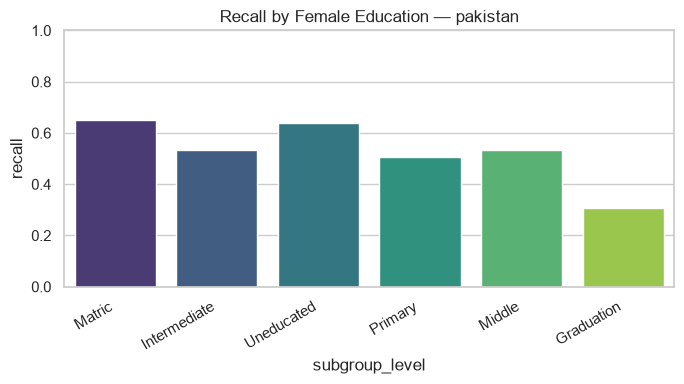


--- By Sufficient Money for Basic Needs ---
  subgroup_level     n  n_positive_true  recall  precision  reliable
0             No  1436              877  0.5405     0.6270      True
1            Yes  1360              904  0.6062     0.7117      True
Saved figure: C:\maternal-mental-health-risk\reports\figures\pakistan\pakistan_fairness_Sufficient_Money_for_Basic_Needs.png


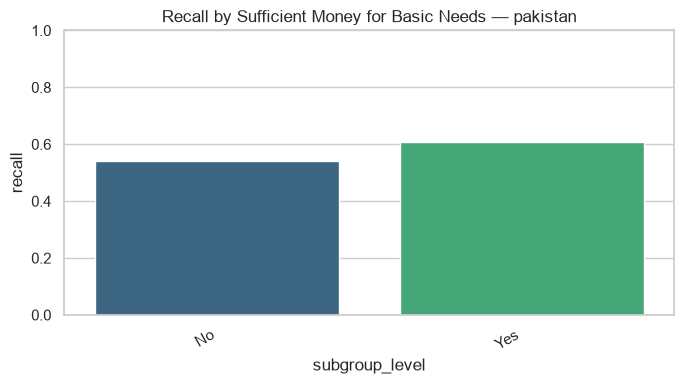

In [3]:
tables_pk = run_fairness_analysis(
    "pakistan", os.path.join(PROCESSED_DIR, "pakistan"),
    subgroup_cols=["Female Education", "Sufficient Money for Basic Needs"])


arab5_depression  (threshold=0.55)

--- By EducationLevel ---
   subgroup_level    n  n_positive_true  recall  precision  reliable
0               2  235               95  0.5368      0.573      True
1               1   66               37  0.6757      0.625      True
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_depression\arab5_depression_fairness_EducationLevel.png


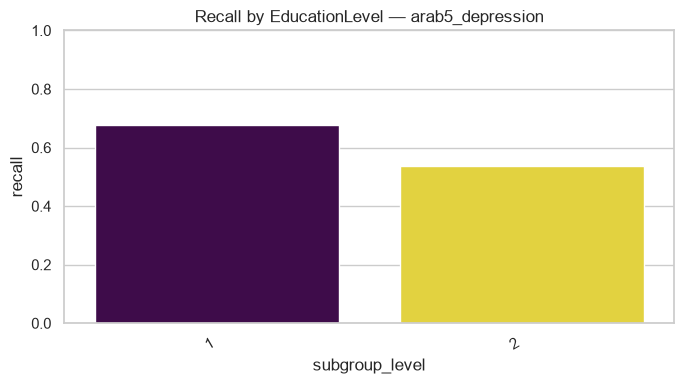


--- By FamilyIncome1 ---
   subgroup_level    n  n_positive_true  recall  precision  reliable
0               1  183               88  0.6932     0.5701      True
1               2  118               44  0.3409     0.6818      True
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_depression\arab5_depression_fairness_FamilyIncome1.png


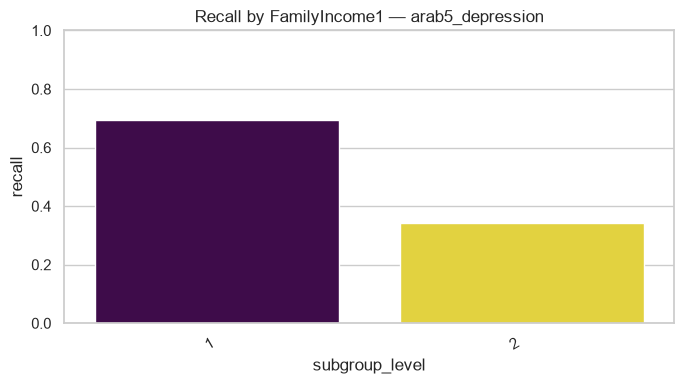

In [4]:
tables_ar_dep = run_fairness_analysis(
    "arab5_depression", os.path.join(PROCESSED_DIR, "arab5_depression"),
    subgroup_cols=["EducationLevel", "FamilyIncome1"])


arab5_anxiety  (threshold=0.45)

--- By EducationLevel ---
   subgroup_level    n  n_positive_true  recall  precision  reliable
0               2  143              100  0.8900     0.8241      True
1               1   48               38  0.9474     0.8372      True
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_anxiety\arab5_anxiety_fairness_EducationLevel.png


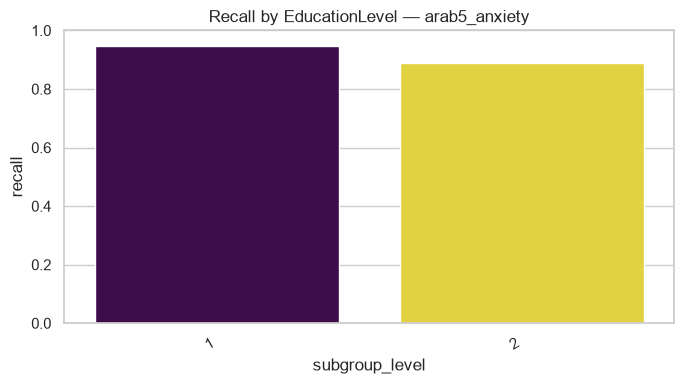


--- By FamilyIncome1 ---
   subgroup_level    n  n_positive_true  recall  precision  reliable
0               1  118               98  0.9388     0.8932      True
1               2   73               40  0.8250     0.6875      True
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_anxiety\arab5_anxiety_fairness_FamilyIncome1.png


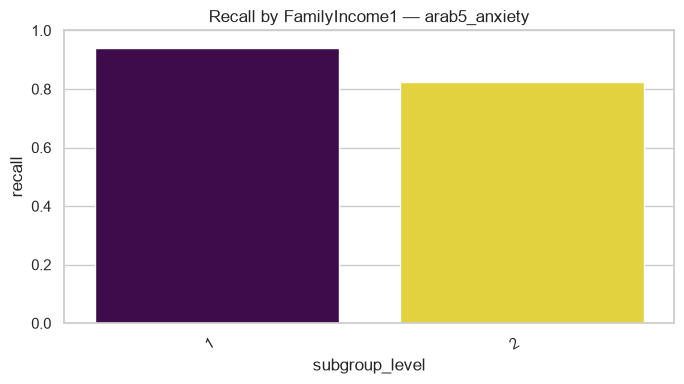

In [5]:
tables_ar_anx = run_fairness_analysis(
    "arab5_anxiety", os.path.join(PROCESSED_DIR, "arab5_anxiety"),
    subgroup_cols=["EducationLevel", "FamilyIncome1"])


uganda  (threshold=0.55)

--- By education ---
        subgroup_level     n  n_positive_true  recall  precision  reliable
0              O-level  1670              754  0.4642     0.6295      True
1         P5 or Higher   502              246  0.6463     0.6310      True
2              A-level   308              151  0.5894     0.6096      True
3  Lower Primary/ None   244              144  0.5833     0.7568      True
4       Degree/Diploma   117               71  0.8028     0.7125      True
Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\uganda_fairness_education.png


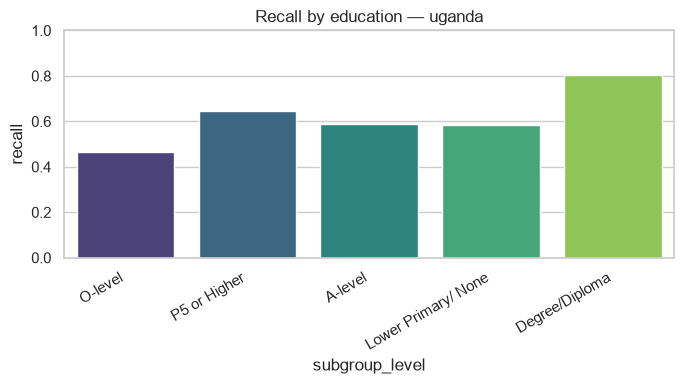


--- By occupation ---
            subgroup_level     n  n_positive_true  recall  precision  reliable
0               Unemployed  1804              820  0.4768     0.6256      True
1  informal business owner   426              191  0.3665     0.6667      True
2    formal business owner   268              137  0.5985     0.6833      True
3        informal employee   180              111  0.8739     0.6510      True
4          formal employee   163              107  0.9252     0.6781      True
Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\uganda_fairness_occupation.png


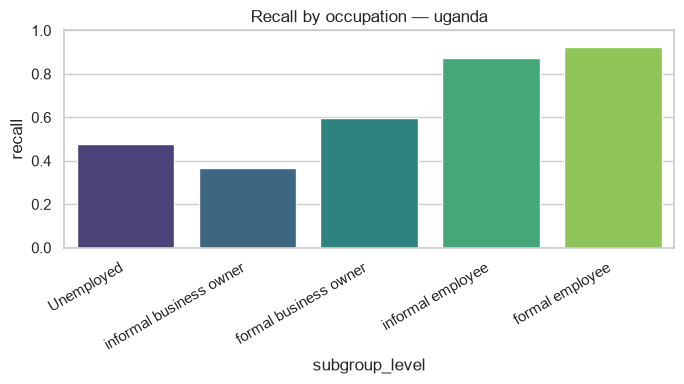

In [6]:
tables_ug = run_fairness_analysis(
    "uganda", os.path.join(PROCESSED_DIR, "uganda"),
    subgroup_cols=["education", "occupation"])

In [7]:
test_ar_dep = pd.read_csv(os.path.join(PROCESSED_DIR, "arab5_depression", "test.csv")).reset_index(drop=True)
test_pred_ar_dep = pd.read_csv(os.path.join(PROCESSED_DIR, "arab5_depression", "base_predictions_test.csv")).reset_index(drop=True)
thr_ar_dep = thresholds_df.loc[thresholds_df["dataset"] == "arab5_depression", "threshold"].values[0]

y_pred_ar_dep = (test_pred_ar_dep["rf"].values >= thr_ar_dep).astype(int)
country_table = subgroup_performance_table(test_pred_ar_dep["y_true"].values, y_pred_ar_dep,
                                            test_ar_dep["part1_country"], min_group_size=10)
print(country_table)
country_table.to_csv(os.path.join(TABLES_DIR, "arab5_depression_fairness_by_country.csv"), index=False)

   subgroup_level   n  n_positive_true  recall  precision  reliable
0               1  87               46  0.5000     0.6053      True
1               2  82               39  0.7692     0.6000      True
2               4  69               29  0.4828     0.6364      True
3               8  35                7  0.4286     0.3333      True
4               6  28               11  0.5455     0.6000      True
